## Transformer: BERT и GPT

## План
1. Механизм Attention - Attention is all you need
2. Отличие трансформера от RNN с Attention
3. Архитектура трансформера. Имплементация (позиционное кодирование: синусоидальное и RoPE)
4. Модели, основанные на энкодере трансформера. BERT. Self-attention
5. Модели, основанные на декодере трансформера. GPT. Cross-attention. Teacher forcing
6. Маскирование. Multi-head attention

Датасет возьмём из известного репозитория Карпаты [nanoGPT](https://github.com/karpathy/nanoGPT)

In [1]:
!pip install -q datasets==2.21.0 transformers nltk

In [2]:
import matplotlib.pyplot as plt

import datasets

In [3]:
text = datasets.load_dataset('karpathy/tiny_shakespeare', trust_remote_code=True)['train']['text']

In [4]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import sent_tokenize

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\azk.work\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\azk.work\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\azk.work\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [5]:
sentences = sent_tokenize(' '.join(text), language='english')
train_sentences = sentences[:10000]
test_sentences = sentences[10000:]

In [6]:
len(train_sentences), len(test_sentences)

(10000, 993)

In [7]:
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer
import torch

class CustomDataset(Dataset):
    def __init__(self, data, tokenizer, max_length = 128):
        self.data = data
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        input_ids = self.tokenizer(self.data[idx], return_tensors = 'pt', max_length = self.max_length, truncation=True).input_ids[0]
        input_ids, labels = input_ids[:-1], input_ids[1:]
        attention_mask = torch.ones_like(input_ids, dtype=torch.bool)
        return {
            "input_ids": input_ids,
            "labels": labels,
            "attention_mask": attention_mask,
        }

In [8]:
from torch.nn.utils.rnn import pad_sequence

def data_collator(examples, padding_value=0, max_length=2048):
    def trim_and_pad(seq, batch_first=True, padding_value=0):
        return pad_sequence([s[:max_length] for s in seq], batch_first=batch_first, padding_value=padding_value)

    input_ids = trim_and_pad(
        [example["input_ids"] for example in examples],
        batch_first=True,
        padding_value=padding_value,
    )
    targets = trim_and_pad(
        [example["labels"] for example in examples],
        batch_first=True,
        padding_value=-100,
    )
    attention_mask = trim_and_pad(
        [example["attention_mask"] for example in examples],
        batch_first=True,
        padding_value=0,
    )
    return {
        "input_ids": input_ids,
        "labels": targets,
        "attention_mask": attention_mask,
    }

In [9]:
tokenizer = GPT2Tokenizer.from_pretrained("openai-community/gpt2")
tokenizer.pad_token = tokenizer.unk_token

In [10]:
from functools import partial

In [11]:
max_length = 32
train_dataset = CustomDataset(train_sentences, tokenizer, max_length=max_length)
test_dataset = CustomDataset(test_sentences, tokenizer, max_length=max_length)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle = True, collate_fn=partial(data_collator, padding_value=tokenizer.pad_token_id, max_length=max_length))
test_loader = DataLoader(test_dataset, batch_size=64, shuffle = False, collate_fn=partial(data_collator, padding_value=tokenizer.pad_token_id, max_length=max_length))

In [12]:
train_dataset[1]

{'input_ids': tensor([3237,   25,  198, 5248,  461,   11, 2740]),
 'labels': tensor([  25,  198, 5248,  461,   11, 2740,   13]),
 'attention_mask': tensor([True, True, True, True, True, True, True])}

In [13]:
batch = next(iter(train_loader))

In [14]:
tokenizer.batch_decode(batch["input_ids"])

['Wot you what, my lord<|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|>',
 'Fear and be slain; no worse can come to fight:\nAnd fight and die is death destroying death;\nWhere fearing dying pays death servile breath',
 'LEONTES:\nYou are married<|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|>',
 'Teeth hadst thou in thy head when thou wast born,\nTo signify thou camest to bite the world:\nAnd, if the rest be',
 'ISABELLA:\nPeace and prosperity<|endoftext|><|endoftext|><|endoftext|

In [15]:
batch["labels"][:5]

tensor([[  313,   345,   644,    11,   616, 15876,    30,  -100,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100],
        [  290,   307, 27029,    26,   645,  4785,   460,  1282,   284,  1907,
            25,   198,  1870,  1907,   290,  4656,   318,  1918, 13897,  1918,
            26,   198,  8496, 33188,  9950, 13831,  1918,  1113,   576,  8033,
            13],
        [35830,  1546,    25,   198,  1639,   389,  6405,    30,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100],
        [ 2788,   550,   301, 14210,   287, 11906,  1182,   618, 14210, 25057,
          4642,    11,   198,  2514, 44078, 14210, 12172,   395,   284, 13197,
           262,   995,    25,   198,  1870,    11,   611,   262,  1334,   307,
 

In [16]:
batch["attention_mask"].sum(1)

tensor([ 7, 31,  8, 31,  9, 20, 19, 26, 16, 31, 17, 31, 31,  4, 31,  7, 22, 16,
        18,  6, 28,  4, 28, 19, 13,  6, 31, 25,  7,  6, 17, 31, 12, 31, 20,  2,
        31, 31, 19,  9,  4, 31, 31, 31,  8, 20, 28,  7, 31, 15, 25, 12,  3, 23,
        31, 31, 21, 25,  3, 31,  6,  8, 27,  8])

# 0. Вспоминаем прошлое занятие

<img src='attn_rnn.png'/>

# 1. Механизм Attention - Attention is all you need

* Статья: [Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)
* Архиполезная [схема](https://jalammar.github.io/illustrated-transformer/)

## Слой аттеншена, a.k.a. One-Head Scaled Dot-Product Self-Attention

- Каждый элемент выборки $X$ - последовательность фичей $x_i \in \mathbb{R}^D$ переменной длины: $X = \{x_1, x_2, \ldots, x_{n_i}\}$
- То есть $X$ это матрица: $X \in \mathbb{R}^{n_i 	imes D}$
- Параметры слоя - матрицы фиксированного размера: $W_Q, W_K, W_V \in \mathbb{R}^{D 	imes d}$
- Вычисление:
    - $Q = X W_Q$ размера $n_i 	imes d_k$
    - $K = X W_K$ размера $n_i 	imes d_k$
    - $V = X W_V$ размера $n_i 	imes d_v$
- $Q, K$ можно нормализовать



## Attention это "мягкий словарь"

- `{key1: value1, key2: value2, ...}`
- **Query** - запрос на поиск среди **Key**
- Пусть $q_i$ и $k_j$ нормализованы: $\|q_i\| = \|k_j\| = 1$
- Тогда $\alpha_{ij}=\langle q_i, k_j \rangle = \cos(\theta)$, где $\theta$ - угол между $q_i$ и $k_j$, можно мерить косинусную схожесть
- Мы хотим померить релевантность всех ключей $k_j, j \in [d]$ запросу $q_i$
- Ответом на $i$-тый запрос будет вернуть линейную комбинацию всех **Value** с найденными скорами релевантности $\alpha_{ij}$

<img src="attention_example.svg" style="width:75%">


$$
\text{Attention}(Q, K, V) = \operatorname{Row-Wise\ Softmax}\left(\dfrac{Q K^\top}{\sqrt{d_k}}\right) V
$$

*Почему такая нормализация?*
$$
q \sim \mathrm{N}(0, \sigma^2), k \sim \mathrm{N}(0, \sigma^2) \rightarrow \mathbb{V} \left[ \sum_{i=1}^{d_k} q_i k_i\right] = \sum_{i=1}^{d_k} \mathbb{V} \left[  q_i k_i\right] = \sum_{i=1}^{d_k} \mathbb{V}\left[  q_i\right]\mathbb{V} \left[k_i\right]= \sigma^4 d_k
$$
Стандартное отклонение будет пропорционально $\sigma \sqrt{d_k}$, отсюда нормализация.

Если мы не уменьшим дисперсию обратно до $\sigma^2$, то софтмакс по логитам уже насытится до $1$ для одного случайного элемента и $0$ для всех остальных. Градиенты через softmax затухнут, так что мы не сможем выучить параметры должным образом.

На $\sigma$ мы не масштабируем, так как при инициализации весов обычно $\sigma << 1$.

In [17]:
# Игрушечный "мягкий словарь": одна запись - пара (key, value)
keys   = torch.tensor([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0]])
values = torch.tensor([[10.0, 0.0], [0.0, 10.0], [-10.0, 0.0], [0.0, -10.0]])

d = keys.shape[-1]

# query почти совпадает с key_1: жёсткий словарь вернул бы ровно value_1,
# attention вернёт смесь всех значений, но с доминирующим value_1
query = torch.tensor([[0.9, 0.1]])
weights = (query @ keys.T / d ** 0.5).softmax(-1)
print("веса:", weights)
print("ответ:", weights @ values)

веса: tensor([[0.4272, 0.2426, 0.1196, 0.2106]])
ответ: tensor([[3.0753, 0.3199]])


In [18]:
# query посередине между key_1 и key_2: веса делятся почти пополам,
# ответ - почти среднее value_1 и value_2
query = torch.tensor([[0.7, 0.7]])
weights = (query @ keys.T / d ** 0.5).softmax(-1)
print("веса:", weights)
print("ответ:", weights @ values)

веса: tensor([[0.3645, 0.3645, 0.1355, 0.1355]])
ответ: tensor([[2.2908, 2.2908]])


<img src="attn_scheme.png" width=700/>

# 2. Отличие трансформера от RNN с Attention

Классический seq2seq (например, [Sutskever et al., 2014](https://arxiv.org/abs/1409.3215)) работал так:

- **Энкодер** - RNN, которая читает исходную последовательность токен за токеном и сжимает всю информацию в последнее скрытое состояние $h_T$
- **Декодер** - RNN, которая генерирует целевую последовательность, начиная с $h_T$ в качестве начального состояния

Проблема: один вектор $h_T$ - бутылочное горлышко, всё предложение должно уместиться в него. Решение из [Bahdanau et al., 2014](https://arxiv.org/abs/1409.0473): на каждом шаге $t$ декодер смотрит attention'ом на **все** скрытые состояния энкодера:

$$
\alpha_{ti} = \operatorname{softmax}_i\left(\text{score}(s_t, h_i)\right), \quad c_t = \sum_i \alpha_{ti} h_i, \quad \text{score}(s_t, h_i) = v^\top \tanh(W s_t + U h_i)
$$

и предсказывает токен из $[s_t; c_t]$. Обратите внимание: $\text{score}(s_t, h_i)$ - это по сути тот же dot-product attention.

## Делим keys и values

- В RNN скрытое состояние $h_i = f(h_{i-1}, x_i)$ - это смесь всех предыдущих эмбеддингов: рекуррентная сеть перемешивает всё прошлое в один вектор
- При этом $h_i$ играет сразу две роли: и то, **по чему искать** (по нему считается $\text{score}(s_t, h_i)$), и то, **что читать** (из него собирается $c_t$)
- Трансформер делает это явным: из каждого $x_i$ вычисляются **три разные проекции**
    - $q_i = x_i W_Q$ - что я хочу найти
    - $k_i = x_i W_K$ - как меня искать, что я "объявляю" о себе
    - $v_i = x_i W_V$ - что я отдаю, если на меня посмотрели
- Релевантность меряется между $Q$ и $K$, а читается из $V$: адресация (поиск) отделена от содержимого (чтения) и больше не склеены в одном рекуррентном векторе

## Идеи, которые позволяют избавиться от рекуррентности

1. **Self-attention** - раньше attention был только между декодером и энкодером. Теперь последовательность ходит attention'ом сама к себе, и это единственный механизм смешивания информации между позициями. Взаимодействие пары позиций - одно скалярное произведение $\langle q_i, k_j \rangle$, для всех пар сразу - матричное умножение $QK^\top$
2. **Позиция - явно, а не порядком обработки.** В RNN позиция токена неявно задавалась номером шага рекуррентности. Без рекуррентности её нужно добавить отдельно - позиционные эмбеддинги (см. следующий раздел)
3. **Постоянная длина пути** между любыми двумя позициями: сигнал от токена $x_1$ до $x_L$ в RNN проходит $O(L)$ последовательных шагов и затухает, в self-attention - один слой. Отсюда же параллелизм: все позиции обрабатываются одновременно, нет зависимости шага $t+1$ от шага $t$

Из [статьи](https://arxiv.org/abs/1706.03762):

| Layer type | Complexity per layer | Sequential operations | Maximum path length |
|---|---|---|---|
| Recurrent | $O(n \cdot d^2)$ | $O(n)$ | $O(n)$ |
| Self-Attention | $O(n^2 \cdot d)$ | $O(1)$ | $O(1)$ |

Заметьте: асимптотика у self-attention **хуже** ($O(L^2)$ против $O(L)$). Побеждают не асимптотика, а параллелизм и постоянный путь градиента.

In [19]:
import time
import torch
import torch.nn as nn

torch.manual_seed(0)
L, D, B = 512, 256, 32
x = torch.randn(B, L, D)

rnn = nn.RNN(D, D, batch_first=True)
qkv_proj = nn.Linear(D, 3 * D)

t0 = time.time()
_ = rnn(x)[0]
t_rnn = time.time() - t0

t0 = time.time()
q, k, v = qkv_proj(x).chunk(3, dim=-1)
_ = (q @ k.transpose(-1, -2)).softmax(-1) @ v
t_att = time.time() - t0

print(f"RNN: {t_rnn:.3f}s, attention: {t_att:.3f}s")

RNN: 0.075s, attention: 0.058s


Вычисление $h_{t+1}$ в RNN **невозможно** начать до окончания шага $t$, а attention целиком состоит из матричных умножений, которые распараллеливаются на GPU.

Это позволило масштабировать обучение на корпуса текстов, что было бы недостижимо для RNN.

# 3. Архитектура трансформера. Имплементация

Классический трансформер из статьи - это **энкодер-декодер**:

- Энкодер - стек из $N$ одинаковых блоков: self-attention (без масок, кроме паддинга) + FeedForward, каждый с residual connection и LayerNorm
- Декодер - стек из $N$ блоков, в каждом **три** подслоя: masked self-attention (токен не видит будущее), **cross-attention** к выходам энкодера и FeedForward

Дальше соберём его по частям: сначала позиционные эмбеддинги, потом attention, потом блоки.

## Positional Encoding
В оригинальном [Трансформере](https://arxiv.org/abs/1706.03762) предложили абсолютные периодические позиционные эмбеддинги:

$$\text{emb}(p, 2i) = \sin(\frac{p}{10000^{2i/d}})$$
$$\text{emb}(p, 2i + 1) = \cos(\frac{p}{10000^{2i/d}})$$
где $p, 2i, 2i+1$ - индексы элемента последовательности, $d$ - длина последовательности.
Они плохо шкалируются на длины за границей тренировочных данных, поэтому появилось много других методов, рассмотрим далее ставший стандартом [RoPE](https://arxiv.org/abs/2104.09864).

In [20]:
import torch
import torch.nn as nn
import math
import numpy as np
from tqdm.auto import tqdm
import torch.nn.functional as F

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, seq_len):
        super().__init__()
        self.d_model = d_model
        self.seq_len = seq_len
        # Create a matrix of shape (seq_len, d_model)
        pe = torch.zeros(seq_len, d_model)
        # Create a vector of shape (seq_len)
        position = torch.arange(0, seq_len, dtype=torch.float).unsqueeze(1) # (seq_len, 1)
        # Create a vector of shape (d_model)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)) # (d_model / 2)
        # Apply sine to even indices
        pe[:, 0::2] = torch.sin(position * div_term) # sin(position * (10000 ** (2i / d_model))
        # Apply cosine to odd indices
        pe[:, 1::2] = torch.cos(position * div_term) # cos(position * (10000 ** (2i / d_model))
        # Add a batch dimension to the positional encoding
        pe = pe.unsqueeze(0) # (1, seq_len, d_model)
        # Register the positional encoding as a buffer
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + (self.pe[:, :x.shape[1], :]) # (batch, seq_len, d_model)
        return x

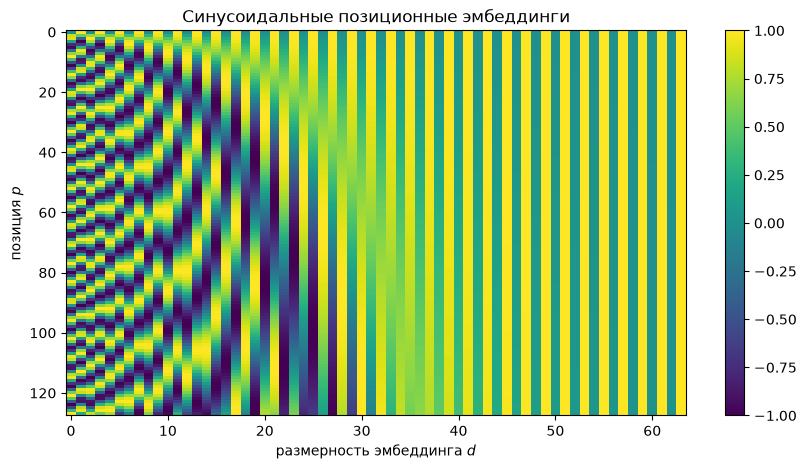

In [21]:
pe = PositionalEncoding(d_model=64, seq_len=128)
plt.figure(figsize=(10, 5))
plt.imshow(pe.pe[0].numpy(), aspect='auto')
plt.xlabel('размерность эмбеддинга $d$')
plt.ylabel('позиция $p$')
plt.title('Синусоидальные позиционные эмбеддинги')
plt.colorbar()
plt.show()

Каждая размерность - синусоида со своей частотой: низкие размерности меняются быстро, высокие - медленно. Позиция восстанавливается как уникальный "узор" из значений синусоид, поэтому $\text{emb}(p + k)$ выражается линейной комбинацией $\text{emb}(p)$ и $\text{emb}(k)$ - модели проще выучивать относительные смещения.

## RoPE
<img src="rope.png" style="width:600px">

RoPE (Rotary Position Embedding) - это способ кодирования позиционной информации в трансформерах, который использует вращательные преобразования для улучшения моделирования отношений между токенами. Вместо прибавления позиционных эмбеддингов к токенам, RoPE вращает их, учитывая относительную позицию токенов в последовательности. Для пары токенов $x_i, x_j$ фазовая разница учитывается напрямую через скалярное произведение, сохраняя относительное расположение токенов:

$$
\operatorname{RoPE}(x) = \begin{bmatrix} x^{(1)} \cos \theta - x^{(2)} \sin \theta \\ x^{(1)} \sin \theta + x^{(2)} \cos \theta \end{bmatrix},
$$


где $\theta=\text{freq}(i)$ определяется в зависимости от позиции $i$ и масштабируется для каждой частоты. Такой подход позволяет трансформеру эффективно обрабатывать как локальные, так и дальние зависимости, улучшая качество на задачах с длинным контекстом.

RoPE вращает только $Q$ и $K$: позиционная информация нужна там, где считается сходство $\langle q_i, k_j \rangle$, - после softmax она уже не нужна.

In [22]:
from typing import Optional, Tuple
def precompute_freqs_cis(dim: int, end: int, theta: float = 10000.0):
    """
    Precompute the frequency tensor for complex exponentials (cis) with given dimensions.

    This function calculates a frequency tensor with complex exponentials using the given dimension 'dim'
    and the end index 'end'. The 'theta' parameter scales the frequencies.
    The returned tensor contains complex values in complex64 data type.

    Args:
        dim (int): Dimension of the frequency tensor.
        end (int): End index for precomputing frequencies.
        theta (float, optional): Scaling factor for frequency computation. Defaults to 10000.0.

    Returns:
        torch.Tensor: Precomputed frequency tensor with complex exponentials.

    """
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)  # type: ignore
    freqs = torch.outer(t, freqs).float()  # type: ignore
    freqs_cis = torch.polar(torch.ones_like(freqs), freqs)  # complex64
    return freqs_cis


def reshape_for_broadcast(freqs_cis: torch.Tensor, x: torch.Tensor):
    """
    Reshape frequency tensor for broadcasting it with another tensor.

    This function reshapes the frequency tensor to have the same shape as the target tensor 'x'
    for the purpose of broadcasting the frequency tensor during element-wise operations.

    Args:
        freqs_cis (torch.Tensor): Frequency tensor to be reshaped.
        x (torch.Tensor): Target tensor for broadcasting compatibility.

    Returns:
        torch.Tensor: Reshaped frequency tensor.

    Raises:
        AssertionError: If the frequency tensor doesn't match the expected shape.
        AssertionError: If the target tensor 'x' doesn't have the expected number of dimensions.
    """
    ndim = x.ndim
    assert 0 <= 1 < ndim
    assert freqs_cis.shape == (x.shape[1], x.shape[-1]), f'{freqs_cis.shape} - {(x.shape[1], x.shape[-1])}'
    shape = [d if i == 1 or i == ndim - 1 else 1 for i, d in enumerate(x.shape)]
    return freqs_cis.view(*shape)


def apply_rotary_emb(
    xq: torch.Tensor,
    xk: torch.Tensor,
    freqs_cis: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Apply rotary embeddings to input tensors using the given frequency tensor.

    This function applies rotary embeddings to the given query 'xq' and key 'xk' tensors using the provided
    frequency tensor 'freqs_cis'. The input tensors are reshaped as complex numbers, and the frequency tensor
    is reshaped for broadcasting compatibility. The resulting tensors contain rotary embeddings and are
    returned as real tensors.

    Args:
        xq (torch.Tensor): Query tensor to apply rotary embeddings.
        xk (torch.Tensor): Key tensor to apply rotary embeddings.
        freqs_cis (torch.Tensor): Precomputed frequency tensor for complex exponentials.

    Returns:
        Tuple[torch.Tensor, torch.Tensor]: Tuple of modified query tensor and key tensor with rotary embeddings.
    """
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = reshape_for_broadcast(freqs_cis, xq_)
    xq_out = torch.view_as_real(xq_ * freqs_cis).flatten(3)
    xk_out = torch.view_as_real(xk_ * freqs_cis).flatten(3)
    return xq_out.type_as(xq), xk_out.type_as(xk)

Так это встраивается в attention (заметьте: `view` превращает подвекторы длины $d_{head}$ в комплексные числа, т.е. пары соседних размерностей вращаются как точки на плоскости):

In [23]:
class MultiHeadAttentionRoPE(nn.Module):
    def __init__(self, d_model, n_heads, qkv_bias = True):
        super().__init__()
        assert d_model % n_heads == 0, "d_model is not divisible by h"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.query = nn.Linear(d_model, d_model, bias = qkv_bias)
        self.key = nn.Linear(d_model, d_model, bias = qkv_bias)
        self.value = nn.Linear(d_model, d_model, bias = qkv_bias)
        self.out = nn.Linear(d_model, d_model)
        self.scale = self.d_head ** -0.5

    def forward(self, x):
        B, L, D = x.shape
        query = self.query(x).view(B, L, self.n_heads, self.d_head)
        key = self.key(x).view(B, L, self.n_heads, self.d_head)
        value = self.value(x).view(B, L, self.n_heads, self.d_head).transpose(1,2)
        query, key = apply_rotary_emb(query, key, precompute_freqs_cis(self.d_head, 4096)[:L].to(next(iter(self.query.parameters())).device))
        query = query.transpose(1,2)
        key = key.transpose(1,2)

        dots = (query @ key.transpose(-1, -2)) * self.scale

        mask = torch.tril(torch.ones((L, L))).to(x.device)
        dots.masked_fill_(mask == 0, float('-inf'))

        att_scores = dots.softmax(-1)
        att_v = att_scores @ value

        out = att_v.permute(0, 2, 1, 3).contiguous().view(B, L, D)

        out = self.out(out)

        return out

## Attention с масками

Реализуем attention так, чтобы он подошёл и энкодеру, и декодеру. Два вида масок:

- `is_causal` - треугольная маска: токен не видит будущие позиции (декодер, GPT)
- `attention_mask` - маска паддинга на ключах: на паддинг смотреть нельзя (батчи из последовательностей разной длины)

А для cross-attention добавим отдельный аргумент `context`: **Q** из $x$, а **K** и **V** из `context`. Если `context` не передан - это self-attention.

In [24]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, qkv_bias = True):
        super().__init__()
        assert d_model % n_heads == 0, "d_model is not divisible by h"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.query = nn.Linear(d_model, d_model, bias = qkv_bias)
        self.key = nn.Linear(d_model, d_model, bias = qkv_bias)
        self.value = nn.Linear(d_model, d_model, bias = qkv_bias)
        self.out = nn.Linear(d_model, d_model)
        self.scale = self.d_head ** -0.5

    def forward(self, x, context = None, attention_mask = None, is_causal = False, return_attention = False):
        """
        x - запросы: (B, L_q, D)
        context - откуда берутся K и V: (B, L_k, D); None = self-attention
        attention_mask - маска паддинга на ключах: (B, L_k), 1 - реальный токен, 0 - паддинг
        is_causal - треугольная маска: токен не видит будущие позиции
        """
        B, L_q, D = x.shape
        context = x if context is None else context
        L_k = context.shape[1]

        query = self.query(x).view(B, L_q, self.n_heads, self.d_head).permute(0, 2, 1, 3)
        key = self.key(context).view(B, L_k, self.n_heads, self.d_head).permute(0, 2, 1, 3)
        value = self.value(context).view(B, L_k, self.n_heads, self.d_head).permute(0, 2, 1, 3)

        dots = (query @ key.transpose(-1, -2)) * self.scale  # (B, H, L_q, L_k)

        if is_causal:
            mask = torch.tril(torch.ones((L_q, L_q), device = x.device))
            dots = dots.masked_fill(mask == 0, float('-inf'))
        if attention_mask is not None:
            pad_mask = attention_mask[:, None, None, :] == 0  # (B, 1, 1, L_k)
            dots = dots.masked_fill(pad_mask, float('-inf'))

        att_scores = dots.softmax(-1)
        att_v = att_scores @ value

        out = att_v.permute(0, 2, 1, 3).contiguous().view(B, L_q, D)
        out = self.out(out)

        if return_attention:
            return out, att_scores
        return out

## Энкодер

Блок энкодера = self-attention + FeedForward, каждый подслой с residual connection и LayerNorm. Обратите внимание: энкодерный self-attention **каузальной маски не имеет** - каждый токен видит всю последовательность целиком, маскируется только паддинг.

In [25]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, qkv_bias = True):
        super().__init__()
        self.layer_norm_1 = nn.LayerNorm(d_model)
        self.layer_norm_2 = nn.LayerNorm(d_model)

        self.MHA = MultiHeadAttention(d_model, n_heads, qkv_bias)
        self.MLP = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.ReLU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x, attention_mask = None):
        # self-attention без causal-маски: токен видит весь контекст, маскируется только паддинг
        x = self.layer_norm_1(self.MHA(x, attention_mask = attention_mask)) + x
        x = self.layer_norm_2(self.MLP(x)) + x

        return x


class TransformerEncoder(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_blocks, qkv_bias = True, seq_len = 2048):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos = PositionalEncoding(d_model, seq_len)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, n_heads, qkv_bias) for _ in range(n_blocks)])
        self.final_ln = nn.LayerNorm(d_model)

    def forward(self, x, attention_mask = None):
        x = x.to(next(iter(self.parameters())).device)
        emb = self.pos(self.embedding(x))

        for block in self.blocks:
            emb = block(emb, attention_mask = attention_mask)

        return self.final_ln(emb)

## Декодер

Блок декодера из оригинальной статьи - **три** подслоя:

1. **Masked self-attention** - токены декодера общаются между собой, но causal-маской каждому запрещено смотреть правее своей позиции
2. **Cross-attention** - **Q** берётся из декодера, **K и V** из выходов энкодера (`memory`): каждый токен декодера "подсматривает" в исходную последовательность. Маска - от паддинга энкодера
3. **FeedForward**

In [26]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, qkv_bias = True):
        super().__init__()
        self.layer_norm_1 = nn.LayerNorm(d_model)
        self.layer_norm_2 = nn.LayerNorm(d_model)
        self.layer_norm_3 = nn.LayerNorm(d_model)

        self.self_MHA = MultiHeadAttention(d_model, n_heads, qkv_bias)
        self.cross_MHA = MultiHeadAttention(d_model, n_heads, qkv_bias)
        self.MLP = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.ReLU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x, memory, attention_mask = None, memory_attention_mask = None):
        # masked self-attention: декодер не имеет права смотреть на будущие токены
        x = self.layer_norm_1(self.self_MHA(x, attention_mask = attention_mask, is_causal = True)) + x
        # cross-attention: Q - из декодера, K и V - из выходов энкодера
        x = self.layer_norm_2(self.cross_MHA(x, context = memory, attention_mask = memory_attention_mask)) + x
        x = self.layer_norm_3(self.MLP(x)) + x

        return x


class TransformerDecoder(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_blocks, qkv_bias = True, seq_len = 2048):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos = PositionalEncoding(d_model, seq_len)
        self.blocks = nn.ModuleList([DecoderBlock(d_model, n_heads, qkv_bias) for _ in range(n_blocks)])
        self.final_ln = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, x, memory, attention_mask = None, memory_attention_mask = None):
        x = x.to(next(iter(self.parameters())).device)
        emb = self.pos(self.embedding(x))

        for block in self.blocks:
            emb = block(emb, memory, attention_mask = attention_mask, memory_attention_mask = memory_attention_mask)

        return self.lm_head(self.final_ln(emb))


class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model, n_heads, n_blocks, seq_len = 2048):
        super().__init__()
        self.encoder = TransformerEncoder(src_vocab_size, d_model, n_heads, n_blocks, seq_len = seq_len)
        self.decoder = TransformerDecoder(tgt_vocab_size, d_model, n_heads, n_blocks, seq_len = seq_len)

    def forward(self, src_ids, tgt_ids, src_attention_mask = None, tgt_attention_mask = None):
        memory = self.encoder(src_ids, attention_mask = src_attention_mask)
        return self.decoder(tgt_ids, memory, attention_mask = tgt_attention_mask, memory_attention_mask = src_attention_mask)

In [27]:
# Проверка формы: энкодер и декодер могут иметь разную длину последовательностей
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
D_MODEL = 128
N_HEADS = 4
N_BLOCKS = 2

transformer = Transformer(src_vocab_size = 1000, tgt_vocab_size = 1000, d_model = D_MODEL, n_heads = N_HEADS, n_blocks = N_BLOCKS, seq_len = 64).to(DEVICE)

src_ids = torch.randint(0, 1000, (2, 10))  # 10 токенов исходного языка
tgt_ids = torch.randint(0, 1000, (2, 8))   # 8 токенов целевого языка
out = transformer(src_ids.to(DEVICE), tgt_ids.to(DEVICE))
print(out.shape)  # (2, 8, 1000): для каждой позиции декодера - распределение над словарём

torch.Size([2, 8, 1000])


# 4. Модели, основанные на энкодере трансформера. BERT

[BERT](https://arxiv.org/abs/1810.04805) (Bidirectional Encoder Representations from Transformers) - это стек энкодерных блоков из классического трансформера. Декодера нет: задача BERT - не генерировать текст, а строить представления токенов, которые потом дообучаются под конкретную задачу (классификация, NER, QA: предобучили - навесили головку - дообучили).

Два отличия от классического энкодера:

1. **Self-attention полный, без causal-маски** - каждый токен видит контекст и слева, и справа. Отсюда "B" в названии
2. **Другая предобучающая задача.** Авторегрессия тут не подходит: модель видит будущее, прятать нечего. Вместо неё - Masked Language Modeling: часть токенов входа замазывается, модель угадывает их по оставшимся

Спецтокены (для `bert-base-uncased`):
- `[CLS]` (id 101) - приписывается в начало, его финальное представление используется как вектор всего предложения для классификации
- `[SEP]` (id 102) - разделяет два предложения (для NSP и QA)
- `[MASK]` (id 103) - замазанный токен
- `[PAD]` (id 0) - паддинг, на него не смотрим через `attention_mask` (та самая padding mask)

In [28]:
from transformers import BertTokenizer

bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
encoded = bert_tokenizer(train_sentences[0], max_length = 32, truncation = True)
print(encoded.input_ids)
print(bert_tokenizer.convert_ids_to_tokens(encoded.input_ids))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

c:\Users\azk.work\Miniconda3\envs\torch\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\azk.work\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[101, 2034, 6926, 1024, 2077, 2057, 10838, 2151, 2582, 1010, 2963, 2033, 3713, 1012, 102]
['[CLS]', 'first', 'citizen', ':', 'before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', '[SEP]']


### Masked Language Modeling

Правило маскирования из статьи: случайно выбираем 15% токенов, и для каждого из них
- с вероятностью 80% - заменяем на `[MASK]`
- с вероятностью 10% - заменяем на случайный токен
- с вероятностью 10% - оставляем как есть

Почему не 100% `[MASK]`? При файнтюне и инференсе `[MASK]` во входе не встречается. Если бы модель видела его 100% времени, у неё сформировались бы "замазанные" представления, не совпадающие с реальными. Разбавление случайными и нетронутыми токенами заставляет модель держать представления полезными для **любого** входа.

Лейблы: на незамаскированных позициях ставим `-100` - по умолчанию эти позиции игнорируются `nn.CrossEntropyLoss`.

In [29]:
def mask_tokens(inputs, tokenizer, mlm_probability = 0.15):
    """
    inputs: (B, L) - батч токенизированных последовательностей
    Возвращает (inputs, labels): испорченные входы и лейблы (-100 на незамаскированных позициях)
    """
    labels = inputs.clone()
    probability_matrix = torch.full(labels.shape, mlm_probability)
    special_tokens_mask = [
        tokenizer.get_special_tokens_mask(val, already_has_special_tokens = True) for val in labels.tolist()
    ]
    # [CLS], [SEP], [PAD] маскировать нельзя
    probability_matrix.masked_fill_(torch.tensor(special_tokens_mask, dtype = torch.bool), value = 0.0)
    masked_indices = torch.bernoulli(probability_matrix).bool()
    labels[~masked_indices] = -100

    # 80% - заменяем на [MASK]
    indices_replaced = torch.bernoulli(torch.full(labels.shape, 0.8)).bool() & masked_indices
    inputs[indices_replaced] = tokenizer.convert_tokens_to_ids(tokenizer.mask_token)

    # 10% - заменяем на случайный токен
    indices_random = torch.bernoulli(torch.full(labels.shape, 0.5)).bool() & masked_indices & ~indices_replaced
    random_words = torch.randint(len(tokenizer), labels.shape, dtype = torch.long)
    inputs[indices_random] = random_words[indices_random]

    # остальные 10% - оставляем как есть
    return inputs, labels

In [30]:
class RawTextDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


def bert_data_collator(examples, tokenizer, max_length = 64):
    batch = tokenizer(examples, max_length = max_length, truncation = True, padding = 'max_length', return_tensors = 'pt')
    inputs, labels = mask_tokens(batch.input_ids, tokenizer)
    return {
        "input_ids": inputs,
        "labels": labels,
        "attention_mask": batch.attention_mask,  # padding mask: 1 - токен, 0 - [PAD]
    }

In [31]:
class BERT(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_blocks, seq_len = 512):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos = PositionalEncoding(d_model, seq_len)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, n_heads) for _ in range(n_blocks)])
        self.final_ln = nn.LayerNorm(d_model)
        self.mlm_head = nn.Linear(d_model, vocab_size)

    def forward(self, input_ids, attention_mask = None):
        emb = self.pos(self.embedding(input_ids))

        for block in self.blocks:
            emb = block(emb, attention_mask = attention_mask)

        return self.mlm_head(self.final_ln(emb))

В настоящем BERT позиционные и сегментные эмбеддинги обучаемые, а поверх энкодера стоит NSP-голова (предсказание, является ли второе предложение следующим за первым). Мы берём наши синусоидальные эмбеддинги и только MLM - на маленьком корпусе это уже видно.

In [34]:
# маленький корпус и немного эпох - цель показать механизм, а не воспроизвести статью
bert_train_sentences = train_sentences[:2000]

bert_loader = DataLoader(
    RawTextDataset(bert_train_sentences),
    batch_size = 16,
    shuffle = True,
    collate_fn = partial(bert_data_collator, tokenizer = bert_tokenizer, max_length = 64),
)

bert = BERT(len(bert_tokenizer), D_MODEL, N_HEADS, N_BLOCKS, seq_len = 64).to(DEVICE)
bert_loss_fnc = nn.CrossEntropyLoss()  # ignore_index=-100 по умолчанию
bert_optimizer = torch.optim.AdamW(bert.parameters(), lr=1e-4)

In [51]:
bert_losses = []
bert.train()
for epoch in tqdm(range(20)):
    loss_epoch = []
    for batch in tqdm(bert_loader):
        input_ids = batch["input_ids"].to(DEVICE)
        labels_ids = batch["labels"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        preds = bert(input_ids, attention_mask = attention_mask)

        bert_optimizer.zero_grad()
        loss = bert_loss_fnc(preds.view(-1, preds.size(-1)), labels_ids.view(-1))
        loss.backward()
        bert_optimizer.step()
        loss_epoch.append(loss.item())

    print(f'Loss_epoch {epoch + 1}: {np.mean(loss_epoch)}')
    bert_losses.append(np.mean(loss_epoch))

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/125 [00:00<?, ?it/s]

Loss_epoch 1: 5.190201240539551


  0%|          | 0/125 [00:00<?, ?it/s]

Loss_epoch 2: 5.202111995697021


  0%|          | 0/125 [00:00<?, ?it/s]

... (31 outputs left out)

  0%|          | 0/125 [00:00<?, ?it/s]

Loss_epoch 19: 4.956626085281372


  0%|          | 0/125 [00:00<?, ?it/s]

Loss_epoch 20: 4.827485969543457


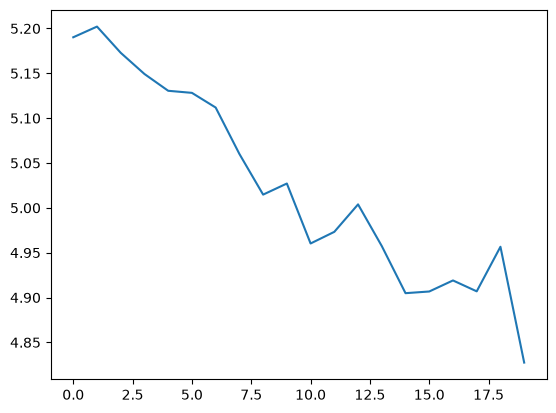

In [52]:
plt.plot(bert_losses)
plt.show()

In [76]:
# проверим MLM: замаскируем слово и попросим BERT его угадать
sentence = train_sentences[8]
encoded = bert_tokenizer(sentence, max_length = 32, truncation = True)

input_ids = torch.tensor(encoded.input_ids)
original_id = input_ids[5].clone()
input_ids[5] = bert_tokenizer.mask_token_id

bert.eval()
with torch.no_grad():
    preds = bert(input_ids[None].to(DEVICE), attention_mask = torch.tensor(encoded.attention_mask)[None].to(DEVICE)).argmax(-1)

print("предложение: ", sentence)
print("замаскировали:", bert_tokenizer.decode([original_id.item()]))
print("BERT угадал:  ", bert_tokenizer.decode([preds[0, 5].item()]))

предложение:  Is't a verdict?
замаскировали: verdict
BERT угадал:   '


Модель учится быстро запоминать частотные слова и только медленно выучивает синтаксис - после нескольких эпох предсказания будут часто правдоподобны, но не обязательно совпадать с оригиналом. Полноценного качества (как у предобученного чекпойнта) на маленьком корпусе не получить, но механизм MLM именно такой.

### Предобученный BERT

Посмотрим на полноценный `bert-base-uncased` (12 слоёв, 768 размерность, 12 голов):

In [ ]:
from transformers import pipeline

fill_mask = pipeline('fill-mask', model = 'bert-base-uncased')
fill_mask("The capital of France is [MASK].")

# 5. Модели, основанные на декодере трансформера. GPT

[GPT](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf) - это декодер классического трансформера, из которого выкинули cross-attention (энкодера нет - нечего подсматривать). Осталась одна модель, которая предсказывает следующий токен по префиксу:

$$P(x_{t+1} \mid x_1, \ldots, x_t)$$

Ключевой момент - декодерная self-attention работает **с causal-маской**: токен не видит правую часть последовательности. Как мы увидим дальше, именно маска позволяет учить все позиции одновременно.

Мы уже написали все нужные детали: `GPTBlock` - это `DecoderBlock` без cross-attention.

### Teacher forcing

Идея родом из эпохи RNN: на каждом шаге обучения подавать на вход модели **истинный предыдущий токен из датасета**, а не то, что модель сама сгенерировала на предыдущем шаге.

- Без teacher forcing ошибка модели на шаге $t$ попадает во вход шага $t+1$ и размножается по всей цепочке - обучение чрезмерно зашумлено
- С teacher forcing каждый шаг учит условное распределение $P(x_{t+1} \mid x_{\le t})$ по **истинному** префиксу, независимо от ошибок модели

В трансформере teacher forcing работает "бесплатно" и **параллельно для всех позиций сразу**:

`labels` - это те же токены, сдвинутые на одну позицию: на позиции $i$ лежит токен, следующий за `input_ids[i]`. По каждому префиксу модель учится предсказывать следующий токен. 

- На вход подаётся весь истинный текст со сдвигом на один токен: `input_ids = tokens[:-1]`, `labels = tokens[1:]` - см `CustomDataset` в начале семинара
- Модель одним прямым проходом получает предсказания для **всех** позиций сразу: по префиксу $x_{\le i}$ предсказать $x_{i+1}$
- causal-маска гарантирует, что позиция $i$ не подсмотрит в токены правее $i$ - иначе модель просто выучила бы "ответ лежит справа"

| | $x_1$ | $x_2$ | $x_3$ | ... | $x_{n-1}$ |
|---|---|---|---|---|---|
| `input_ids` | $x_1$ | $x_2$ | $x_3$ | ... | $x_{n-1}$ |
| `labels` | $x_2$ | $x_3$ | $x_4$ | ... | $x_n$ |

На инференсе teacher forcing не работает: истинных продолжений у нас нет. Модель ходит **авторегрессионно**: предсказывает токен, дописывает его к контексту и повторяет (см. `generate_batch` ниже). Разрыв между "учились на истинных контекстах, а генерируем из своих" называется exposure bias.

<img src="causal_masking.png">

In [ ]:
class GPTBlock(nn.Module):
    def __init__(self, d_model, n_heads, qkv_bias = True):
        super().__init__()
        self.layer_norm_1 = nn.LayerNorm(d_model)
        self.layer_norm_2 = nn.LayerNorm(d_model)

        self.MHA = MultiHeadAttention(d_model, n_heads, qkv_bias)
        self.MLP = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.ReLU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x):
        # is_causal = True: токен не видит будущее. Именно это делает teacher forcing параллельным
        x = self.layer_norm_1(self.MHA(x, is_causal = True)) + x
        x = self.layer_norm_2(self.MLP(x)) + x

        return x


class GPT(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_blocks, qkv_bias = True, seq_len = 2048):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos = PositionalEncoding(d_model, seq_len)
        self.blocks = nn.Sequential(*[GPTBlock(d_model, n_heads, qkv_bias) for _ in range(n_blocks)])
        self.final_ln = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        x = x.to(next(iter(self.parameters())).device)
        emb = self.embedding(x)
        emb = self.pos(emb)

        x = self.blocks(emb)

        out = self.lm_head(self.final_ln(x))

        return out

In [ ]:
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
D_MODEL = 512
N_HEADS = 8
VOCAB_SIZE = len(tokenizer)
N_BLOCKS = 3
model = GPT(VOCAB_SIZE, D_MODEL, N_HEADS, N_BLOCKS, seq_len = max_length).to(DEVICE)

In [ ]:
loss_fnc = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-3, weight_decay = 1e-5)

В обучающем цикле teacher forcing уже спрятан: `input_ids` - истинный префикс, `labels` - истинное продолжение со сдвигом. Модель ни разу не видит собственных предсказаний.

In [ ]:
loss_epochs = []
loss_evals = []
for epoch in tqdm(range(10)):
    loss_epoch = []
    model.train()
    for batch in tqdm(train_loader):
        input_ids = batch["input_ids"].to(DEVICE)
        labels_ids = batch["labels"].to(DEVICE)

        preds = model(input_ids)

        optimizer.zero_grad()
        loss = loss_fnc(preds.view(-1, preds.size(-1)), labels_ids.view(-1))
        loss.backward()
        optimizer.step()
        loss_epoch.append(loss.item())

    loss_eval = []
    with torch.no_grad():
        for batch in tqdm(test_loader):
            input_ids = batch["input_ids"].to(DEVICE)
            labels_ids = batch["labels"].to(DEVICE)

            preds = model(input_ids)

            loss = loss_fnc(preds.view(-1, preds.size(-1)), labels_ids.view(-1))
            loss_eval.append(loss.item())

    print(f'Loss_epoch {epoch + 1}: {np.mean(loss_epoch)}')
    print(f'Loss_eval {epoch + 1}: {np.mean(loss_eval)}')
    loss_epochs.append(np.mean(loss_epoch))
    loss_evals.append(np.mean(loss_eval))

In [ ]:
plt.plot(loss_epochs, label="train")
plt.plot(loss_evals, label="eval")
plt.legend()
plt.show()

При инференсе teacher forcing нет - модель ходит авторегрессионно, один токен за раз. Каждый новый токен требует нового прохода модели (в этом семинаре так и делаем; в продакшене прошлые K/V кешируются - KV cache):

In [ ]:
@torch.no_grad()
def generate_batch(model, ids, is_decode = False, max_length = 20):
    model.eval()
    if type(ids) == list:
        symbols = torch.tensor(ids, device = DEVICE).view(len(ids),1)

    else:
        symbols = torch.tensor(ids, device = DEVICE).view(1,1)

    for _ in range(max_length - 1):

        cur_symbols = model(symbols).argmax(-1)[:, -1][:, None]
        symbols = torch.cat([symbols, cur_symbols], dim = 1)

    if is_decode:
        symbols = tokenizer.batch_decode(symbols, skip_special_tokens=True)
    return symbols

In [ ]:
batch = train_dataset[3]
input_ids, labels_ids = batch["input_ids"], batch["labels"]

In [ ]:
generate_batch(model, ids = input_ids[0].item(), is_decode=True, max_length= 30)

In [ ]:
tokenizer.decode(labels_ids, skip_special_tokens=True)

### А где cross-attention?

В классическом трансформере из раздела 3 декодер, помимо masked self-attention, содержит cross-attention:

- **Q** - проекции скрытых состояний декодера ("что я сейчас хочу узнать")
- **K** и **V** - проекции выходов энкодера ("что есть в исходном предложении")
- маска - от паддинга исходной последовательности: на `[PAD]` энкодера смотреть нельзя

Для перевода это естественно: генерируя очередное слово перевода, декодер каждый раз перечитывает исходное предложение. При этом длины Q и K/V **могут не совпадать** - это нормально для attention:

In [ ]:
cross = MultiHeadAttention(D_MODEL, N_HEADS).to(DEVICE)

decoder_states = torch.randn(1, 5, D_MODEL, device = DEVICE)   # 5 сгенерированных токенов
encoder_memory = torch.randn(1, 12, D_MODEL, device = DEVICE)  # 12 токенов исходного предложения

out, att = cross(decoder_states, context = encoder_memory, return_attention = True)
print(out.shape)  # (1, 5, D_MODEL) - длина декодера сохранилась
print(att.shape)  # (1, n_heads, 5, 12) - каждый токен декодера смотрит на все токены энкодера

GPT от cross-attention отказался: нет энкодера - нет и `memory`. Итого вся классическая архитектура делится на два "кусочка", из которых собраны BERT и GPT:

| | BERT | GPT | классический трансформер |
|---|---|---|---|
| часть | энкодер | декодер | энкодер + декодер |
| self-attention | полный | с causal-маской | полный / с causal-маской |
| cross-attention | нет | нет | есть |
| задача предобучения | MLM: угадать замазанные токены | LM с teacher forcing: угадать следующий токен | LM декодера с teacher forcing |
| применение | представления под задачи (классификация, QA) | генерация текста | перевод, seq2seq |

# 6. Маскирование. Multi-head attention

Термин "маскирование" в трансформерах означает сразу три разные вещи:

| Где | Что маскируется | Зачем |
|---|---|---|
| **Causal (look-ahead) mask** - self-attention декодера и GPT | позиции правее текущего токена | токен не видит будущее; именно она делает teacher forcing параллельным |
| **Padding mask** - энкодер, декодер, cross-attention | `[PAD]`-токены в батче | паддинг - мусор, на него не смотрим; в HF передаётся как `attention_mask` |
| **`[MASK]`-токены в BERT** | сами входные токены (это НЕ attention-маска) | MLM-задача: угадать замазанное по контексту с двух сторон |

Плюс на инференсе встречаются маски логитов: `no_repeat_ngram_size`, `bad_words_ids` в `model.generate` и т.п. запрещают конкретные токены в выдаче.

In [ ]:
# Веса внимания при разных масках: сырые скоры q @ k^T уже есть, смотрим что делает маска
torch.manual_seed(1)
L = 8
dots = torch.randn(1, L, L)

full = dots.softmax(-1)
causal = dots.masked_fill(torch.tril(torch.ones(L, L)) == 0, float('-inf')).softmax(-1)

pad_ids = torch.tensor([[1, 1, 1, 1, 1, 1, 0, 0]])  # последние два токена - [PAD]
padded = dots.masked_fill(pad_ids[:, None, :] == 0, float('-inf')).softmax(-1)

fig, axes = plt.subplots(1, 3, figsize = (15, 4))
for ax, att, title in zip(axes, [full, causal, padded], ["BERT: без масок", "GPT: causal mask", "padding mask"]):
    ax.imshow(att[0].numpy(), vmin = 0, vmax = 1)
    ax.set_title(title)
plt.show()

print("сумма весов строки у causal-маски всегда 1, но веса правее диагонали - нули:")
print(causal[0, 2])

Заметьте: маска реализуется через `-inf` **до** softmax - после него запрещённые веса становятся ровно нулями, и на их места не идёт градиент. Прибавлять нули после softmax было бы ошибкой: они не нормализуют оставшиеся веса.

Свяжем всё вместе:

- **Teacher forcing** - про обучение авторегрессионных моделей (RNN seq2seq, GPT): вход - истинный префикс, лейбл - следующий токен. В RNN его приходилось разворачивать шаг за шагом; в трансформере все позиции учатся параллельно одним проходом
- **Causal mask** - то, что делает параллельный teacher forcing в трансформере возможным: без неё позиция $i$ при параллельном проходе видела бы "правильный ответ" правее себя
- **Padding mask** - везде, где в батче есть паддинг: в self-attention энкодера (BERT), в self-attention и cross-attention декодера
- **`[MASK]`-токены** - только в BERT: это испорченный вход для MLM, а не маска attention. BERT вообще не авторегрессионный, teacher forcing к нему не относится

## Multi-Head Attention (MHA)
<img src="mha_img_original.png" style="width:75%">

- Разделяем каждый вектор из $Q, K, V$ на `num_heads` подвекторов с помощью идентичных линейных проекций $h$ раз ($D \mod h = 0$)
- Применяем Attention независимо, соединяем результаты

$$
\begin{align*}
\text{Multihead}(Q, K, V) = \textrm{concat} \left( \text{head}_1, \text{head}_2, \ldots, \text{head}_h \right) W_O,\\
\text{head}_i = \text{Attention}(Q_i, K_i, V_i), i = [h]; W_O \in \mathbb{R}^{h d_v \times d_{out}}
\end{align*}
$$
- **Можно ли написать без цикла?** Да - все головы живут в тех же матрицах $W_Q, W_K, W_V$, раскладываются на `n_heads` блоков по $d_{head}$ размерностей (`view` в коде выше) и обрабатываются одной пакетной матричной операцией. Голова - не отдельная нейросеть, а подвектор проекции; каждая голова учит своё "отношение" между токенами (синтаксис, кореференции, позиции - зависит от головы и данных)

Проверим эквивалентность честному циклу по головам:

In [ ]:
torch.manual_seed(0)
mha = MultiHeadAttention(d_model = 16, n_heads = 2)
x = torch.randn(2, 5, 16)

out, att = mha(x, is_causal = True, return_attention = True)

# а теперь то же самое циклом: у каждой головы свои срезы Q, K, V
heads_out = []
for h in range(mha.n_heads):
    sl = slice(h * mha.d_head, (h + 1) * mha.d_head)
    q = mha.query(x)[:, :, sl]
    k = mha.key(x)[:, :, sl]
    v = mha.value(x)[:, :, sl]
    dots = (q @ k.transpose(-1, -2)) * mha.scale
    dots = dots.masked_fill(torch.tril(torch.ones(5, 5)) == 0, float('-inf'))
    heads_out.append(dots.softmax(-1) @ v)

manual = mha.out(torch.cat(heads_out, dim = -1))
print("максимальная разница с циклом по головам:", (out - manual).abs().max().item())

## Итог

- Attention - мягкий словарь: по $Q$ ищем среди $K$, читаем из $V$. В отличие от RNN-attention, keys и values разделены явно
- Классический трансформер - энкодер (полный self-attention) + декодер (masked self-attention + cross-attention). BERT - первый, GPT - второй без cross-attention
- Teacher forcing - способ обучения авторегрессионных моделей на истинных префиксах; в трансформере он параллельный и работает за счёт causal-маски. На инференсе его нет - модель ходит авторегрессионно
- Маски бывают трёх видов: causal (декодер), padding (везде, где паддинг), `[MASK]` (только BERT, и это не attention-маска)
- MHA - несколько heads как подвекторы одной проекции: дёшево, параллельно, каждая голова учит своё отношение между токенами